### Retrospective Labelling - Compare datasets

Objective:
* To analyse which datasets would each model perform best on
  * `train_raw_node_info`: train info but with added node features
  * `train_raw_removed_corr_var`: train info with added node features, but removed highly correlated and low variance features
  * `train_yj_robust_scaled`: train info but removed highly correlated and low variance features, transform highly skewed variables, and applied RobustScaled()

* ran several models: 
  1. Logistic Regression, 
  2. K Nearest Neighbours, 
  3. MLP Classifier, 
  4. LightGBM, 
  5. CatBoost, 
  6. Random Forest

To control class imbalance:
* as the number of illicit rows in the dataset are few (~11% overall)
* When running the train-test-split to evaluate the performance of each model, I stratified the split into `(time_step)_(label)` to ensure that the train-test-split equally captures 20% of all licit and illicit entries of every time step
* I also assessed the model's performance with `PR_AUC` score, as `ROC_AUC` would be influenced to be higher as the illicit classes are a small minority.
-------------
#### Results
I used PR_AUC to assess the performance of each dataset, as the number of illicit classes are few (~11% illicit for total labelled data)

Tree Models:
* CatBoost saw marginal increase in performance of PR_AUC between the raw and removed_cor_var, but removed_cor_var had better performance for precision, recall, and F1 => Pick `train_raw_removed_corr_var`
* LightBGM saw best performance in PR_AUC in raw (slightly better than YJ_robust_scaled) => Pick `train_raw_node_info`
* Random Forest performed marginally better in Raw_removed_corr_var than raw => Pick `train_raw_removed_corr_var`

Others:
* KNN saw big increase in PR_AUC in YJ_robust_scaled => Pick `train_yj_robust_scaled`
* Logistic Regression saw best perfromance in YJ_robust scaled => Pick `train_yj_robust_scaled`
* MLP Classifier showed best performance in YJ_robust_scaled => Pick `train_yj_robust_scaled`

My findings confirm with the existing knowledge that models like Logistic Regression, KNN, and MLP perform better with feature scaling (https://blog.dailydoseofds.com/p/feature-scaling-is-not-always-necessary), while Tree Models do not benefit from Feature Scaling

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import matplotlib.pyplot as plt


In [2]:
### Load data

train_raw = pd.read_csv("train_raw_node_info.csv", header = 0)
train_raw_removed_corr_var = pd.read_csv("train_raw_removed_corr_var.csv", header = 0)
train_yj_robust_scaled = pd.read_csv("train_yj_robust_scaled.csv", header = 0)

In [3]:
display(train_raw.columns)
display(train_raw_removed_corr_var.columns)
display(train_yj_robust_scaled.columns)

Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)

Index(['txId', 'time_step', 'label', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_7', 'feat_10', 'feat_12',
       ...
       'feat_160', 'feat_161', 'feat_162', 'feat_163', 'feat_164', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=110)

Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)

In [4]:
# Use known labels only for supervised evaluation.
known = train_raw.loc[train_raw["label"].notna()].copy()
known["label"] = known["label"].astype(int)

# Stratify on the combination of timestep and label.
strata = (
    known["time_step"].astype(str)
    + "_label_"
    + known["label"].astype(str)
)

# Each timestep-label group needs at least 2 rows to be stratified.
stratum_counts = strata.value_counts()
if (stratum_counts < 2).any():
    raise ValueError(
        "Some time_step/label groups have fewer than 2 rows, "
        "so they cannot be stratified. Check stratum_counts[stratum_counts < 2]."
    )


train_ids, test_ids = train_test_split(
    known["txId"],
    test_size=0.20,
    random_state=100,
    stratify=strata,
)


In [5]:
# Keep labels sourced consistently from train_raw.
y_train = known.set_index("txId").loc[train_ids, "label"]
y_test = known.set_index("txId").loc[test_ids, "label"]

datasets = {
    "Raw": train_raw,
    "Raw_removed_corr_var": train_raw_removed_corr_var,
    "YJ_robust_scaled": train_yj_robust_scaled,
}

excluded = {"txId", "label"}

In [6]:
def get_X_for_ids(df, ids):
    if "txId" not in df.columns:
        raise ValueError("Each dataset must contain a txId column for alignment.")

    indexed = df.set_index("txId", drop=False)

    missing_ids = pd.Index(ids).difference(indexed.index)
    if len(missing_ids):
        raise ValueError(f"{len(missing_ids)} txIds are missing from a dataset.")

    aligned = indexed.loc[ids]
    cols = [
        c for c in aligned.select_dtypes(include=np.number).columns
        if c not in excluded
    ]
    return aligned[cols]

In [7]:
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=100),
    ),

    "LightGBM": LGBMClassifier(
        random_state=100,
        verbosity=-1,
        n_jobs=-1,
    ),

    "CatBoost": CatBoostClassifier(
        random_seed=100,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1,
    ),

    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_jobs=-1),
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(random_state=100, n_jobs=-1),
    ),

    "MLP Classifier": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        MLPClassifier(random_state=100, max_iter=300),
    ),
}

In [8]:
results = []
pr_curves = {}

for dataset_name, df in datasets.items():
    X_train = get_X_for_ids(df, train_ids)
    X_test = get_X_for_ids(df, test_ids)

    for model_name, model in models.items():
        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        precision_curve, recall_curve, _ = precision_recall_curve(y_test, predictions)

        pr_curves[(dataset_name, model_name)] = {
            "precision": precision_curve,
            "recall": recall_curve,
            "average_precision": average_precision_score(y_test, predictions),
        }

        results.append({
            "dataset": dataset_name,
            "model": model_name,
            "ROC_AUC": roc_auc_score(y_test, probabilities),
            "PR_AUC": average_precision_score(y_test, probabilities),
            "precision": precision_score(y_test, predictions, zero_division=0),
            "recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
        })

results_df = pd.DataFrame(results).sort_values(
    ["PR_AUC", "ROC_AUC"],
    ascending=False
)

In [9]:
display(results_df.sort_values(by = ["model", "PR_AUC"], ascending=[True, False]))

,dataset,model,ROC_AUC,PR_AUC,precision,recall,F1
2,Raw,CatBoost,0.998720,0.994743,0.989986,0.949246,0.969188
8,Raw_removed_corr_var,CatBoost,0.998426,0.994650,0.992837,0.950617,0.971268
14,YJ_robust_scaled,CatBoost,0.998477,0.994024,0.991392,0.947874,0.969144
15,YJ_robust_scaled,KNN,0.982639,0.941163,0.921596,0.919067,0.920330
9,Raw_removed_corr_var,KNN,0.978264,0.908611,0.867374,0.897119,0.881996
3,Raw,KNN,0.976151,0.907853,0.870839,0.897119,0.883784
1,Raw,LightGBM,0.999119,0.995546,0.990057,0.956104,0.972784
13,YJ_robust_scaled,LightGBM,0.999066,0.995419,0.991429,0.951989,0.971309
7,Raw_removed_corr_var,LightGBM,0.998891,0.995031,0.991465,0.956104,0.973464
12,YJ_robust_scaled,Logistic Regression,0.991028,0.961198,0.928977,0.897119,0.912770


From above, I used PR_AUC to assess the performance of each dataset, as the number of illicit classes are few (~11% illicit for total labelled data)

### Tree Models:
* CatBoost saw marginal increase in performance of PR_AUC between the raw and removed_cor_var, but removed_cor_var had better performance for precision, recall, and F1 => Pick Raw_removed_corr_var
* LightBGM saw best performance in PR_AUC in raw (slightly better than YJ_robust_scaled) => Pick Raw
* Random Forest performed marginally better in Raw_removed_corr_var than raw => Pick Raw_removed_corr_var

### Others:
* KNN saw big increase in PR_AUC in YJ_robust_scaled => Pick YJ_robust_scaled
* Logistic Regression saw best perfromance in YJ_robust scaled => Pick YJ_robust_scaled
* MLP Classifier showed best performance in YJ_robust_scaled => Pick YJ_robust_scaled

My findings confirm with the existing knowledge that models like Logistic Regression, KNN, and MLP perform better with feature scaling (https://blog.dailydoseofds.com/p/feature-scaling-is-not-always-necessary), while Tree Models do not benefit from Feature Scaling

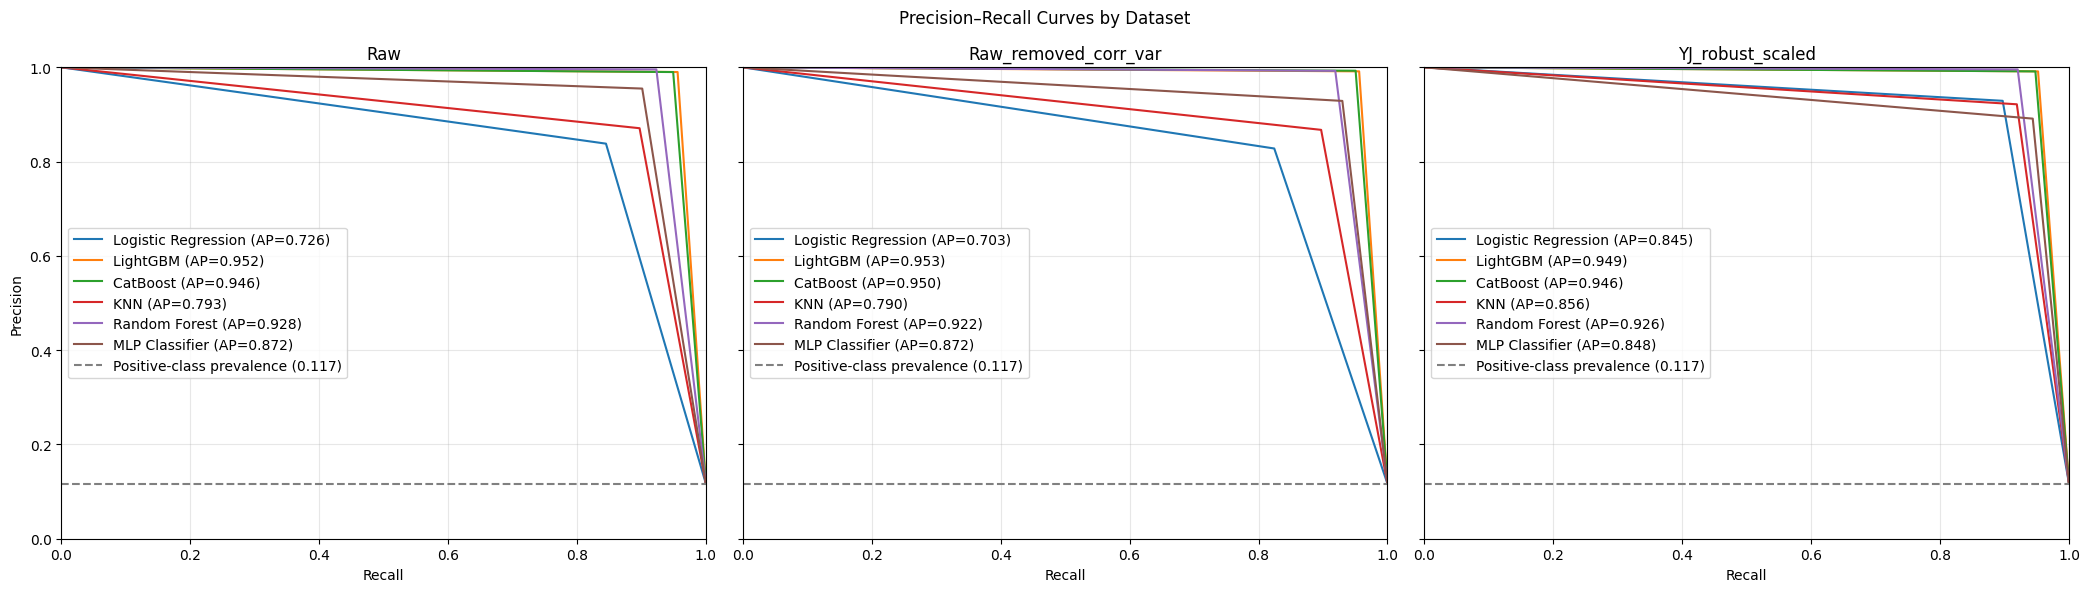

In [10]:
dataset_names = list(datasets.keys())

fig, axes = plt.subplots(
    1, len(dataset_names),
    figsize=(7 * len(dataset_names), 6),
    sharey=True
)

if len(dataset_names) == 1:
    axes = [axes]

for ax, dataset_name in zip(axes, dataset_names):
    for (curve_dataset, model_name), curve in pr_curves.items():
        if curve_dataset != dataset_name:
            continue

        ax.plot(
            curve["recall"],
            curve["precision"],
            label=f'{model_name} (AP={curve["average_precision"]:.3f})'
        )

    # Baseline: prevalence of the positive class in the test split
    ax.axhline(
        y=y_test.mean(),
        color="gray",
        linestyle="--",
        label=f"Positive-class prevalence ({y_test.mean():.3f})"
    )

    ax.set_title(dataset_name)
    ax.set_xlabel("Recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(loc="best")

axes[0].set_ylabel("Precision")
fig.suptitle("Precision–Recall Curves by Dataset")
plt.tight_layout()
plt.show()